In [1]:
import torch

from torch import nn

In [2]:
device = "cuda" if torch.cuda.is_available()  else "cpu"
device

'cpu'

In [3]:
from pathlib import Path

In [4]:
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

In [5]:
import os

def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories, In this folder : {dirpath}, there are : {len(filenames)} images")    
    
walk_through_dir(image_path)

There are 2 directories, In this folder : data\pizza_steak_sushi, there are : 0 images
There are 3 directories, In this folder : data\pizza_steak_sushi\test, there are : 0 images
There are 0 directories, In this folder : data\pizza_steak_sushi\test\pizza, there are : 25 images
There are 0 directories, In this folder : data\pizza_steak_sushi\test\steak, there are : 19 images
There are 0 directories, In this folder : data\pizza_steak_sushi\test\sushi, there are : 31 images
There are 3 directories, In this folder : data\pizza_steak_sushi\train, there are : 0 images
There are 0 directories, In this folder : data\pizza_steak_sushi\train\pizza, there are : 78 images
There are 0 directories, In this folder : data\pizza_steak_sushi\train\steak, there are : 75 images
There are 0 directories, In this folder : data\pizza_steak_sushi\train\sushi, there are : 72 images


In [6]:
# setup train and test path

train_dir = image_path / "train"
test_dir =  image_path / "test"

In [7]:
train_dir, test_dir

(WindowsPath('data/pizza_steak_sushi/train'),
 WindowsPath('data/pizza_steak_sushi/test'))

Random image path: data\pizza_steak_sushi\test\sushi\2394442.jpg
Image class: sushi
Image height: 408
Image width: 512


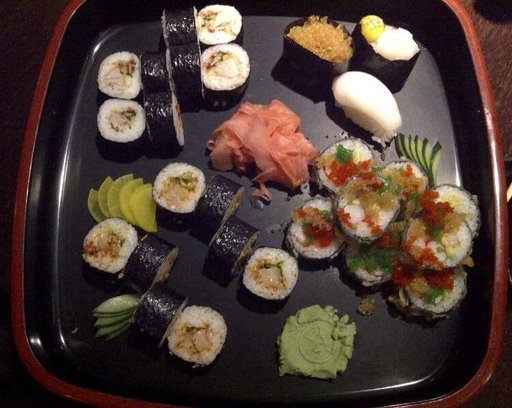

In [8]:
# visualize an image

import random
from PIL import Image


random.seed(42)
image_path_list = list(image_path.glob("*/*/*.jpg"))


random_image_path = random.choice(image_path_list)
image_class = random_image_path.parent.stem

img = Image.open(random_image_path)


print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}") 
print(f"Image width: {img.width}")

img

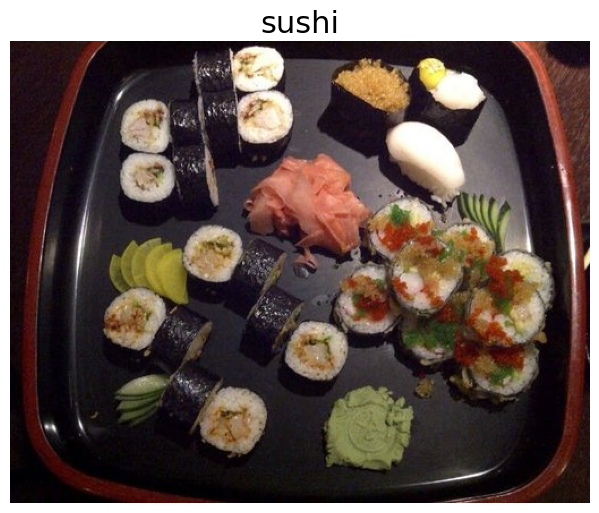

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.imshow(img)
plt.title(image_class, fontsize= 22)
plt.axis('off')
plt.show()

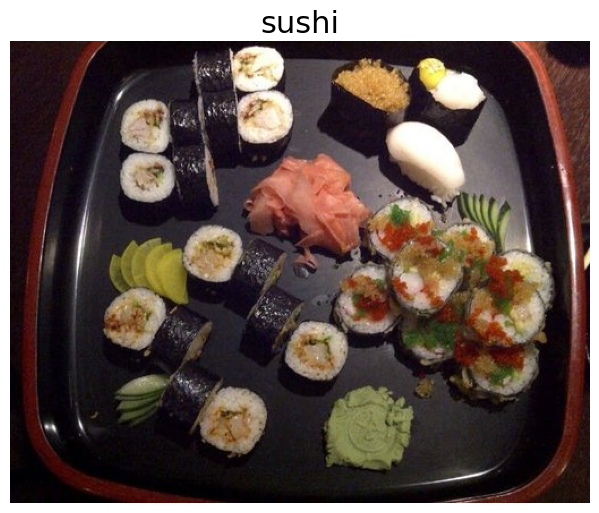

In [10]:
import numpy as np

img_as_array = np.asarray(img)  # Si on veut faire des calculs, modifer des pixels ou préparer l'image pour l'intégrer dans un modéle

plt.figure(figsize=(12, 6))
plt.imshow(img_as_array)
plt.title(image_class, fontsize= 22)
plt.axis('off')
plt.show()

In [11]:
import torch

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [12]:
data_transform = transforms.Compose([
    
                    transforms.Resize(size= (64, 64)),
                    transforms.RandomHorizontalFlip(p= 0.5),
                    transforms.ToTensor()
])




data_transform

Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
)

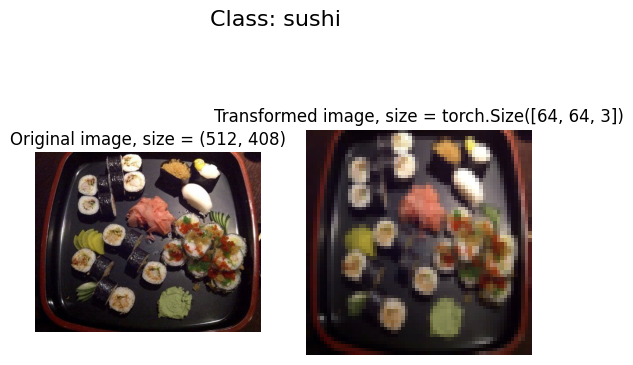

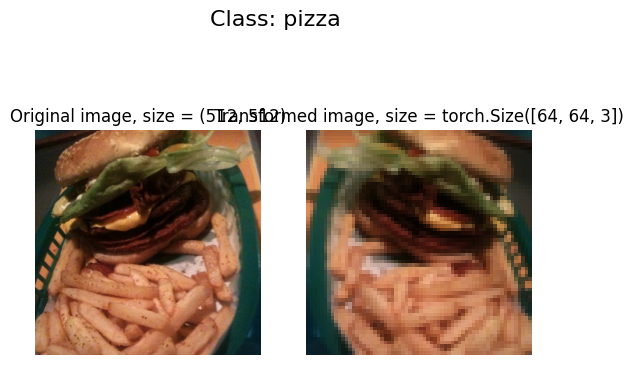

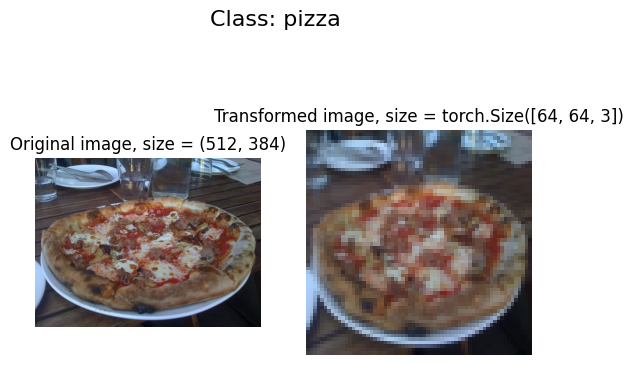

In [13]:
# this function apply this composition on a random sample of the dataset

def plot_transformed_images(image_paths, transform, n= 3, seed= 42):
    random.seed(42)
    
    random_image_paths = random.sample(image_paths, k= n)
    
    for image_path in random_image_paths:
        
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1,2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original image, size = {f.size}")
            ax[0].axis('off')
            
            
            # Transformed images
            transformed_image = transform(f).permute(1, 2, 0) # (PyTorch default is [C, H, W] but Matplotlib is [H, W, C])
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed image, size = {transformed_image.shape}")
            ax[1].axis('off')
            

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)



plot_transformed_images(image_path_list, 
                        transform=data_transform, 
                        n=3)

## Option 1: Loading Image Data using ImageFolder

In [14]:
train_data = datasets.ImageFolder(root = train_dir,
                                    transform= data_transform,
                                    target_transform= None)


test_data = datasets.ImageFolder(root = test_dir,
                                    transform= data_transform)

In [15]:
print(train_data, '\n\n', test_data)

Dataset ImageFolder
    Number of datapoints: 225
    Root location: data\pizza_steak_sushi\train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           ) 

 Dataset ImageFolder
    Number of datapoints: 75
    Root location: data\pizza_steak_sushi\test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )


In [16]:
class_names = train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [17]:
# get class names as a dict
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [18]:
# check length
len(train_data), len(test_data)

(225, 75)

In [19]:
image, label = train_data[0]
print(f"Image tensor {image}")
print(f"Image type : {image.dtype}")
print(f"Image label : {label}")
print(f"Image shape {image.shape}")

Image tensor tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.090

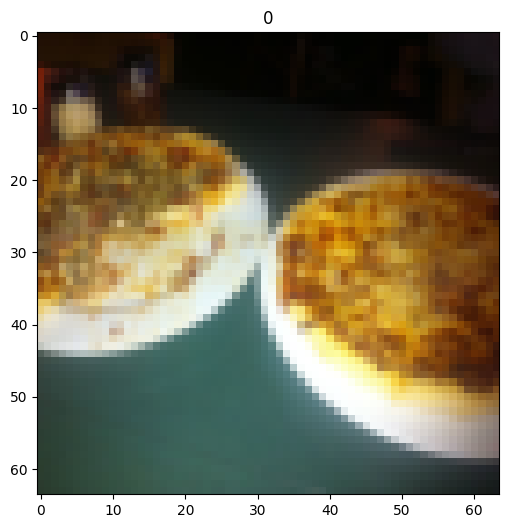

In [20]:
img = image.permute(1, 2, 0)
plt.figure(figsize=(12,6))
plt.imshow(img)
plt.title(label)
plt.show()

In [21]:
# Turn loaded images into DataLoader's

from torch.utils.data import DataLoader

train_dataloader = DataLoader(dataset= train_data,
                                batch_size= 1,
                                num_workers= 1,
                                shuffle= True)

test_dataloader = DataLoader(dataset= test_data,
                                batch_size= 1,
                                num_workers= 1,
                                shuffle= False)


train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x1d499b17ca0>,
 <torch.utils.data.dataloader.DataLoader at 0x1d499b15750>)

In [22]:
img, label = next(iter(train_dataloader))

print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


### Option 2 : create our custom function for loading data instead of using ImageFolder

In [23]:
import os
import pathlib
import torch

from torch.utils.data import Dataset
from torchvision import transforms
from typing import List, Dict, Tuple

In [25]:
# we create a helper function to get class names
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
    
    # 1- get class names
    classes = sorted( entry.name for entry in os.scandir(directory) if entry.is_dir())
    
    # 2- raise an error if class not found
    if not classes:
        raise FileNotFoundError(f"No classes found in this directory {directory}.")
    
    # 3- create a dictionnary of index labels
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    
    
    return classes, class_to_idx




In [27]:
find_classes(train_dir) # test function

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [28]:
# then we create our custom dataset 

class ImageFolderCustom(Dataset):
    # initialize with a targ_dir and transform (optionel)
    def __init__(self, targ_dir: str, transform: None) -> None:
        self.paths = list(pathlib.Path(targ_dir).glob('*/*.jpg'))
        self.transform = transform
        self.classes, self.class_to_idx = find_classes(targ_dir)
        
        
    # make a function to load an image
    def load_image(self, index: int) -> Image.Image :
        image_path = self.paths[index]
        return Image.open(image_path)
        
    # overwrite the method len       
    def __len__(self) -> int:
        return len(self.paths)
    
    # overwrite the method getitem
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        img = self.load_image(index)
        class_name = self.paths[index].parent.name
        class_idx = self.class_to_idx[class_name]
        
        if self.transform:
            return self.transform(img), class_idx
        
        else:
            return img, class_idx

In [29]:
# Augment train data
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

# We don't augment test data, only reshape
test_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [30]:
# to use this custome data
train_data_custom = ImageFolderCustom(train_dir, transform= train_transforms)

test_data_custom = ImageFolderCustom(test_dir, transform= test_transforms)

In [31]:
len(train_data_custom), len(test_data_custom)

(225, 75)

In [32]:
train_data_custom.classes

['pizza', 'steak', 'sushi']

In [34]:
train_data_custom.transform

Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
)

## Other forms of transforms (data agmentation)

In [ ]:
from  torchvision import transforms

train_transforms = transforms.Compose([
    transforms.Resize(size= (224, 224)),
    transforms.TrivialAugmentWide(num_magnitude_bins= 31), # par défaut = 31    
    transforms.ToTensor()
]
)

test_transforms = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.ToTensor()                 # No data augmentation for test data
])


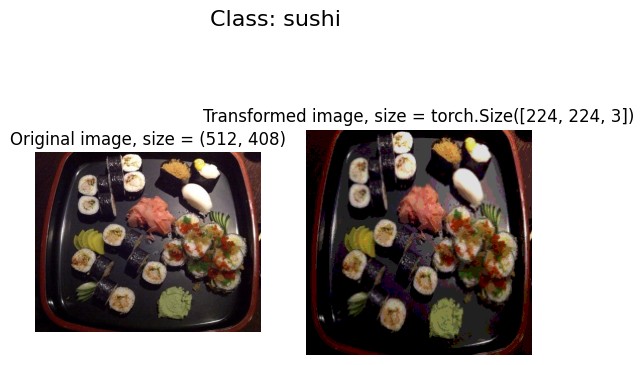

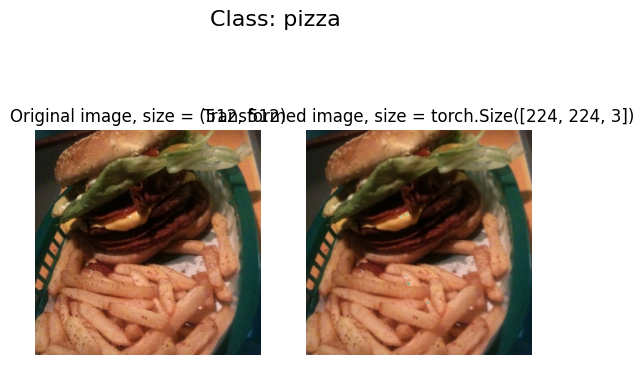

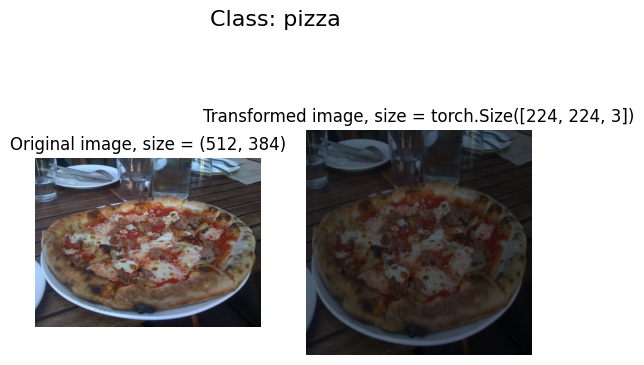

In [42]:
# let's test this
image_path_list = list(image_path.glob('*/*/*.jpg'))
plot_transformed_images(image_paths= image_path_list,
                        transform= train_transforms,
                        n= 3,
                        seed= None)
